# ĐÁNH GIÁ, PHÂN TÍCH LỖI VÀ BÀN GIAO BÁO CÁO LATEX
Đề tài 1 – FIT4013. Mọi metric và hình đều được tính từ đầu ra thực của 03_EDA.ipynb,
không đưa số liệu giả vào báo cáo.
Chạy sau: 01_EDA.ipynb (EDA) → 02_Preprocessing.ipynb → 03_Training.ipynb → 04 này.

Nội dung theo yêu cầu giảng viên: Accuracy, Precision, Recall, F1, Confusion Matrix,
so sánh baseline/phương pháp, lỗi theo lớp và trường hợp văn bản sai, hạn chế, báo cáo LaTeX.

## 1. Đọc kết quả thực nghiệm do Thành viên 3 bàn giao

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import (accuracy_score,precision_recall_fscore_support,
                             confusion_matrix, classification_report)

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd,*cwd.parents] if (p/'results'/'training'/'test_predictions.csv').is_file()),None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Cần chạy 03_Training.ipynb trước để tạo results/training/')
IN_DIR = PROJECT_ROOT/'results'/'training'
OUT_DIR = PROJECT_ROOT/'results'/'evaluation'
FIG_DIR = OUT_DIR/'figures'
REPORT_DIR = PROJECT_ROOT/'report'/'chapters'
for d in (OUT_DIR,FIG_DIR,REPORT_DIR):d.mkdir(parents=True,exist_ok=True)
metrics = pd.read_csv(IN_DIR/'test_metrics.csv')
predictions = pd.read_csv(IN_DIR/'test_predictions.csv')
best_info = json.loads((IN_DIR/'best_model.json').read_text(encoding='utf-8'))
with (PROJECT_ROOT/'results'/'member2_outputs'/'experiment_config.json').open(encoding='utf-8') as f:
    split_info = json.load(f)
LABEL_COL = split_info['target_column']
required = {'model_id','source_index','feedback_text',LABEL_COL,'predicted_label','is_correct'}
if not required.issubset(predictions.columns):
    raise ValueError(f'Thiếu các cột của file dự đoán: {required-set(predictions.columns)}')
assert set(metrics['model_id']) == set(predictions['model_id'])
labels = sorted(set(predictions[LABEL_COL].astype(str))|set(predictions['predicted_label'].astype(str)))
print('Mô hình được chọn bởi CV:',best_info['model_id'])
print('Số cấu hình:',len(metrics),'| Số mẫu test:',predictions['source_index'].nunique())
display(metrics.sort_values('f1_macro',ascending=False).round(4))


Mô hình được chọn bởi CV: TFIDF_Unigram__KNN
Số cấu hình: 10 | Số mẫu test: 245


,model_id,vectorizer,algorithm,hyperparameters,cv_f1_macro,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
1,Baseline_BoW_NB,BoW_Unigram,NaiveBayes,alpha=1,NaN,0.3878,0.3764,0.3751,0.3748,0.3846
2,BoW_Unigram__NaiveBayes,BoW_Unigram,NaiveBayes,"{""model__alpha"": 0.5}",0.3637,0.3837,0.3727,0.3706,0.3702,0.3800
6,TFIDF_Unigram__NaiveBayes,TFIDF_Unigram,NaiveBayes,"{""model__alpha"": 0.5}",0.3374,0.3918,0.3801,0.3683,0.3614,0.3744
3,BoW_Unigram__KNN,BoW_Unigram,KNN,"{""model__n_neighbors"": 5}",0.3555,0.3592,0.3670,0.3618,0.3588,0.3618
4,BoW_Unigram_Bigram__NaiveBayes,BoW_Unigram_Bigram,NaiveBayes,"{""model__alpha"": 0.5}",0.3569,0.3673,0.3557,0.3481,0.3436,0.3549
7,TFIDF_Unigram__KNN,TFIDF_Unigram,KNN,"{""model__n_neighbors"": 5}",0.3647,0.3388,0.3431,0.3427,0.3369,0.3384
8,TFIDF_Unigram_Bigram__NaiveBayes,TFIDF_Unigram_Bigram,NaiveBayes,"{""model__alpha"": 0.5}",0.2852,0.4041,0.4019,0.3639,0.3316,0.3520
9,TFIDF_Unigram_Bigram__KNN,TFIDF_Unigram_Bigram,KNN,"{""model__n_neighbors"": 3}",0.3490,0.3347,0.3479,0.3360,0.3316,0.3349
5,BoW_Unigram_Bigram__KNN,BoW_Unigram_Bigram,KNN,"{""model__n_neighbors"": 7}",0.3433,0.3347,0.3270,0.3275,0.3271,0.3341
0,Dummy_Majority,BoW_Unigram,Dummy,default,NaN,0.4000,0.1333,0.3333,0.1905,0.2286


## 2. So sánh với Baseline (không chỉ dùng Accuracy)
Macro F1 cân bằng đóng góp giữa các lớp; xem thêm Precision/Recall, Accuracy và mô hình Dummy_Majority.
Không diễn giải rằng cấu hình có Accuracy cao nhất chắc chắn tốt nhất.

,model_id,algorithm,vectorizer,cv_f1_macro,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,Baseline_BoW_NB,NaiveBayes,BoW_Unigram,NaN,0.3878,0.3764,0.3751,0.3748,0.3846
1,BoW_Unigram__NaiveBayes,NaiveBayes,BoW_Unigram,0.3637,0.3837,0.3727,0.3706,0.3702,0.3800
2,TFIDF_Unigram__NaiveBayes,NaiveBayes,TFIDF_Unigram,0.3374,0.3918,0.3801,0.3683,0.3614,0.3744
3,BoW_Unigram__KNN,KNN,BoW_Unigram,0.3555,0.3592,0.3670,0.3618,0.3588,0.3618
4,BoW_Unigram_Bigram__NaiveBayes,NaiveBayes,BoW_Unigram_Bigram,0.3569,0.3673,0.3557,0.3481,0.3436,0.3549
5,TFIDF_Unigram__KNN,KNN,TFIDF_Unigram,0.3647,0.3388,0.3431,0.3427,0.3369,0.3384
6,TFIDF_Unigram_Bigram__NaiveBayes,NaiveBayes,TFIDF_Unigram_Bigram,0.2852,0.4041,0.4019,0.3639,0.3316,0.3520
7,TFIDF_Unigram_Bigram__KNN,KNN,TFIDF_Unigram_Bigram,0.3490,0.3347,0.3479,0.3360,0.3316,0.3349
8,BoW_Unigram_Bigram__KNN,KNN,BoW_Unigram_Bigram,0.3433,0.3347,0.3270,0.3275,0.3271,0.3341
9,Dummy_Majority,Dummy,BoW_Unigram,NaN,0.4000,0.1333,0.3333,0.1905,0.2286


Mô hình đã được chọn trước bằng Cross-Validation: TFIDF_Unigram__KNN
Lưu ý: Bảng trên chỉ sắp xếp kết quả test để so sánh, không dùng test để chọn lại mô hình.


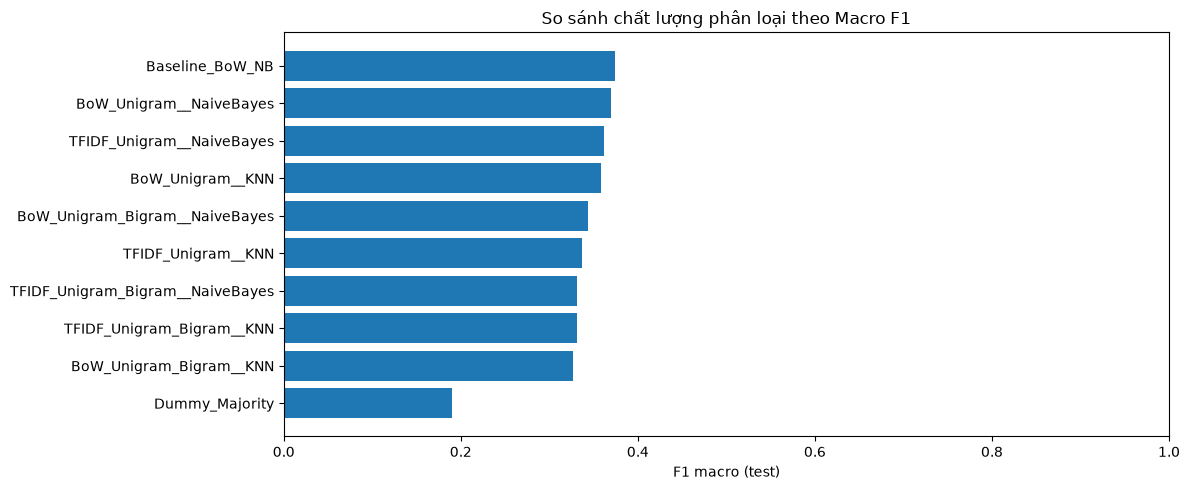

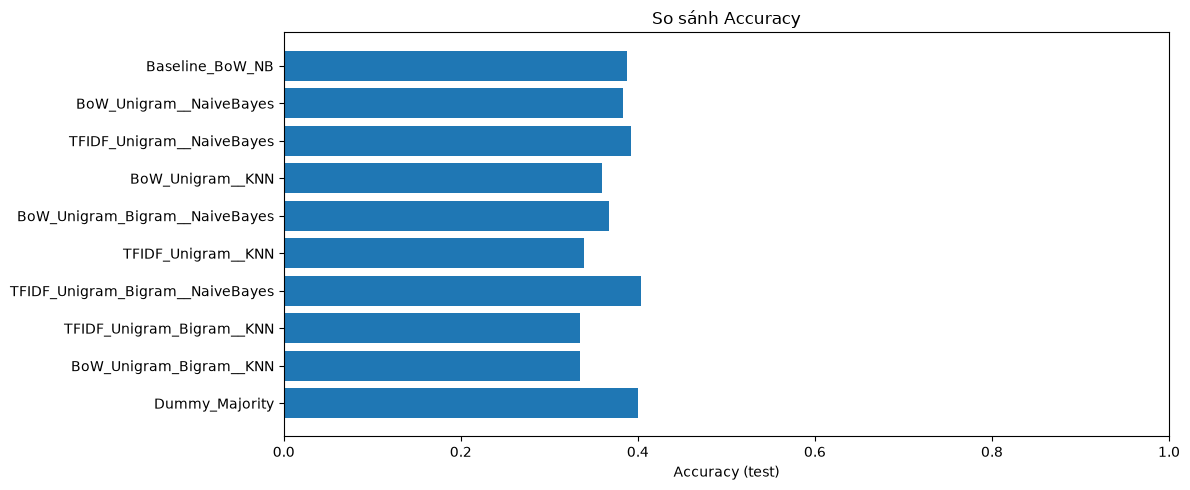

In [2]:
display_cols=['model_id','algorithm','vectorizer','cv_f1_macro','accuracy','precision_macro','recall_macro','f1_macro','f1_weighted']
comparison = metrics[display_cols].sort_values('f1_macro',ascending=False).reset_index(drop=True)
comparison.to_csv(OUT_DIR/'model_comparison.csv',index=False,encoding='utf-8-sig')
display(comparison.round(4))
print(
    "Mô hình đã được chọn trước bằng Cross-Validation:",
    best_info["model_id"]
)

print(
    "Lưu ý: Bảng trên chỉ sắp xếp kết quả test để "
    "so sánh, không dùng test để chọn lại mô hình."
)
fig,ax=plt.subplots(figsize=(12,max(4,len(comparison)*0.5)))
ax.barh(comparison['model_id'][::-1],comparison['f1_macro'][::-1])
ax.set(xlabel='F1 macro (test)',title='So sánh chất lượng phân loại theo Macro F1',xlim=(0,1))
plt.tight_layout()
plt.savefig(FIG_DIR/'model_f1_comparison.png',dpi=180,bbox_inches='tight')
plt.show()
fig,ax=plt.subplots(figsize=(12,max(4,len(comparison)*0.5)))
ax.barh(comparison['model_id'][::-1],comparison['accuracy'][::-1])
ax.set(xlabel='Accuracy (test)',title='So sánh Accuracy',xlim=(0,1))
plt.tight_layout()
plt.savefig(FIG_DIR/'model_accuracy_comparison.png',dpi=180,bbox_inches='tight')
plt.show()


## 3. Phân tích chi tiết theo nhãn và ma trận nhầm lẫn


=== Baseline_BoW_NB ===
              precision    recall  f1-score   support

    negative       0.29      0.27      0.28        73
     neutral       0.39      0.35      0.37        74
    positive       0.45      0.50      0.47        98

    accuracy                           0.39       245
   macro avg       0.38      0.38      0.37       245
weighted avg       0.38      0.39      0.38       245



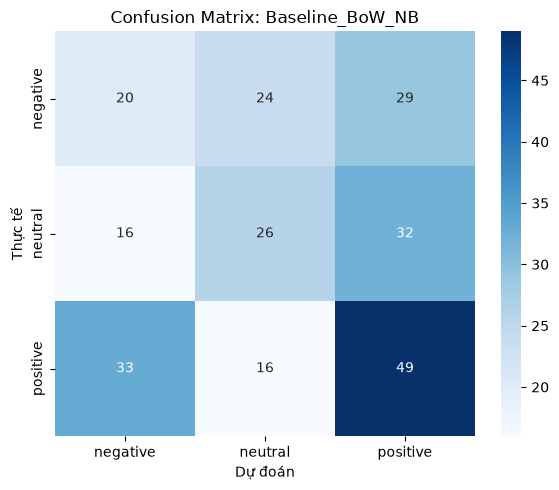


=== TFIDF_Unigram__NaiveBayes ===
              precision    recall  f1-score   support

    negative       0.31      0.22      0.26        73
     neutral       0.42      0.28      0.34        74
    positive       0.41      0.60      0.49        98

    accuracy                           0.39       245
   macro avg       0.38      0.37      0.36       245
weighted avg       0.38      0.39      0.37       245



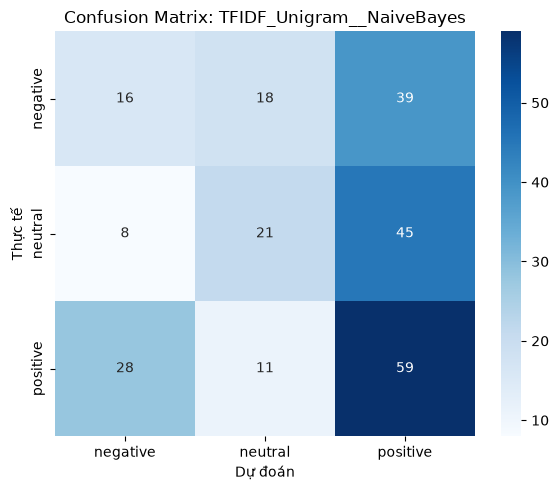


=== TFIDF_Unigram__KNN ===
              precision    recall  f1-score   support

    negative       0.31      0.42      0.36        73
     neutral       0.31      0.30      0.30        74
    positive       0.42      0.31      0.35        98

    accuracy                           0.34       245
   macro avg       0.34      0.34      0.34       245
weighted avg       0.35      0.34      0.34       245



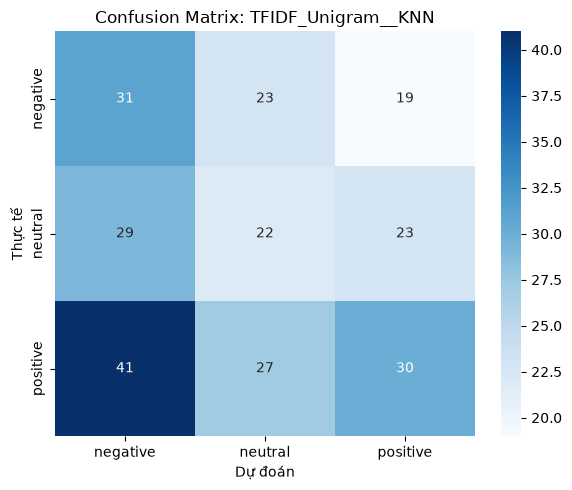

,model_id,label,precision,recall,f1,support
0,Baseline_BoW_NB,negative,0.2899,0.2740,0.2817,73.0
1,Baseline_BoW_NB,neutral,0.3939,0.3514,0.3714,74.0
2,Baseline_BoW_NB,positive,0.4455,0.5000,0.4712,98.0
3,TFIDF_Unigram__NaiveBayes,negative,0.3077,0.2192,0.2560,73.0
4,TFIDF_Unigram__NaiveBayes,neutral,0.4200,0.2838,0.3387,74.0
5,TFIDF_Unigram__NaiveBayes,positive,0.4126,0.6020,0.4896,98.0
6,TFIDF_Unigram__KNN,negative,0.3069,0.4247,0.3563,73.0
7,TFIDF_Unigram__KNN,neutral,0.3056,0.2973,0.3014,74.0
8,TFIDF_Unigram__KNN,positive,0.4167,0.3061,0.3529,98.0


In [3]:
selected_models = list(dict.fromkeys([
    'Baseline_BoW_NB',
    'TFIDF_Unigram__NaiveBayes',
    'TFIDF_Unigram__KNN',
    best_info['model_id']
]))
selected_models = [m for m in selected_models if m in set(predictions['model_id'])]
all_reports=[]; confusion_rows=[]
for model_id in selected_models:
    part=predictions.loc[predictions['model_id']==model_id]
    y_true=part[LABEL_COL].astype(str)
    y_pred=part['predicted_label'].astype(str)
    report=classification_report(y_true,y_pred,labels=labels,output_dict=True,zero_division=0)
    print('\n===',model_id,'===')
    print(classification_report(y_true,y_pred,labels=labels,zero_division=0))
    for label in labels:
        values=report[label]
        all_reports.append({'model_id':model_id,'label':label,
                            'precision':values['precision'],'recall':values['recall'],
                            'f1':values['f1-score'],'support':values['support']})
    cm=confusion_matrix(y_true,y_pred,labels=labels)
    fig,ax=plt.subplots(figsize=(6,5))
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=labels,yticklabels=labels,ax=ax)
    ax.set(xlabel='Dự đoán',ylabel='Thực tế',title=f'Confusion Matrix: {model_id}')
    plt.tight_layout()
    plt.savefig(FIG_DIR/f'cm_{model_id}.png',dpi=180,bbox_inches='tight')
    plt.show()
    for i,true_label in enumerate(labels):
        for j,pred_label in enumerate(labels):
            confusion_rows.append({'model_id':model_id,'true_label':true_label,
                                   'pred_label':pred_label,'count':int(cm[i,j])})
report_df=pd.DataFrame(all_reports)
confusion_df=pd.DataFrame(confusion_rows)
report_df.to_csv(OUT_DIR/'per_class_metrics.csv',index=False,encoding='utf-8-sig')
confusion_df.to_csv(OUT_DIR/'confusion_matrix_counts.csv',index=False,encoding='utf-8-sig')
display(report_df.round(4))

## 4. Error Analysis – các trường hợp dự đoán sai
Nhìn lớp nào hay nhầm với lớp nào, xem câu gốc và nhãn dự đoán.
Không mặc định câu sai vì mỉa mai, nhiễu hoặc thiếu dữ liệu: chỉ nêu đó là giả thuyết sau khi đọc ví dụ cụ thể.

In [4]:
best_pred=predictions.loc[predictions['model_id']==best_info['model_id']].copy()
wrong=best_pred.loc[best_pred[LABEL_COL].astype(str)!=best_pred['predicted_label'].astype(str)].copy()
wrong['confusion_pair']=wrong[LABEL_COL].astype(str)+' → '+wrong['predicted_label'].astype(str)
print('Tổng số mẫu sai của mô hình chọn theo CV:',len(wrong),'/',len(best_pred))
confusion_pairs=wrong['confusion_pair'].value_counts().rename_axis('true_to_pred').reset_index(name='count')
display(confusion_pairs)
wrong.to_csv(OUT_DIR/'error_cases_all.csv',index=False,encoding='utf-8-sig')
examples=(wrong.groupby('confusion_pair',group_keys=False).head(3)
          .sort_values(['confusion_pair','source_index']))
display(examples[['source_index','feedback_text',LABEL_COL,'predicted_label','confusion_pair']])
examples.to_csv(OUT_DIR/'error_examples.csv',index=False,encoding='utf-8-sig')
confusion_pairs.to_csv(OUT_DIR/'confusion_pairs.csv',index=False,encoding='utf-8-sig')


Tổng số mẫu sai của mô hình chọn theo CV: 162 / 245


,true_to_pred,count
0,positive → negative,41
1,neutral → negative,29
2,positive → neutral,27
3,negative → neutral,23
4,neutral → positive,23
5,negative → positive,19


,source_index,feedback_text,sentiment_label,predicted_label,confusion_pair
1727,829,Actually large employee likely child lose stro...,negative,neutral,negative → neutral
1723,1048,Each condition two high marriage beyond detail.,negative,neutral,negative → neutral
1731,1102,Everyone relate day business return organizati...,negative,neutral,negative → neutral
1755,542,Before development rise main black represent f...,negative,positive,negative → positive
1754,674,Her deep yeah then difference source student o...,negative,positive,negative → positive
1738,897,Respond suggest pressure suggest control new w...,negative,positive,negative → positive
1729,164,Trade leader option interview cultural center ...,neutral,negative,neutral → negative
1733,189,Such last operation ability message age often ...,neutral,negative,neutral → negative
1719,382,Reveal its million teacher now agree.,neutral,negative,neutral → negative
1757,378,Act provide such anyone financial stage.,neutral,positive,neutral → positive


## 5. NHẬN XÉT VÀ PHÂN TÍCH KẾT QUẢ THỰC NGHIỆM

### 5.1. Đánh giá tổng quan hiệu quả mô hình

Trong quá trình thực nghiệm, nhóm tiến hành so sánh hai thuật toán phân loại là Multinomial Naive Bayes và K-Nearest Neighbors (K-NN), kết hợp với các phương pháp biểu diễn văn bản Bag-of-Words (BoW) và TF-IDF.

Dữ liệu được chia thành 978 mẫu huấn luyện và 245 mẫu kiểm thử. Việc lựa chọn tham số được thực hiện bằng phương pháp Stratified 3-Fold Cross-Validation trên tập huấn luyện, sử dụng Macro F1-score làm tiêu chí đánh giá.

Kết quả cho thấy mô hình **TF-IDF Unigram kết hợp K-NN với k = 5** đạt Macro F1 trung bình cao nhất trên Cross-Validation là **0,3647**, nhỉnh hơn cấu hình BoW Unigram kết hợp Naive Bayes (0,3637). Tuy nhiên, mức chênh lệch chỉ khoảng 0,0010, nên chưa đủ cơ sở để khẳng định một phương pháp vượt trội ổn định.

Khi đánh giá trên tập kiểm thử, mô hình được lựa chọn đạt kết quả:

| Chỉ số | Kết quả |
|---|---:|
| Accuracy | 0,3388 |
| Precision (Macro) | 0,3431 |
| Recall (Macro) | 0,3427 |
| F1-score (Macro) | 0,3369 |

Trong tổng số 245 mẫu kiểm thử, mô hình dự đoán đúng 83 mẫu và dự đoán sai 162 mẫu, tương ứng tỷ lệ chính xác 33,88%.

Trong khi đó, mô hình baseline sử dụng BoW Unigram kết hợp Multinomial Naive Bayes đạt Accuracy 0,3878 và Macro F1-score 0,3748.

Như vậy, Macro F1-score của mô hình được chọn bằng Cross-Validation thấp hơn baseline khoảng 0,0379 trên tập kiểm thử.

Kết quả này cho thấy việc đạt điểm Cross-Validation cao nhất không bảo đảm mô hình cũng đạt kết quả tốt nhất trên dữ liệu kiểm thử. Nhóm cần xem xét tính ổn định của kết quả, thay vì chỉ dựa vào một cấu hình có điểm CV nhỉnh hơn.

Ngoài ra, mô hình DummyClassifier dự đoán nhãn phổ biến nhất đạt Accuracy 0,4000 nhưng Macro F1-score chỉ đạt 0,1905. Điều này minh họa rằng Accuracy cao hơn không đồng nghĩa với khả năng phân biệt tốt giữa cả ba lớp cảm xúc.

### 5.2. Phân tích kết quả theo từng nhãn

Dựa trên Classification Report của mô hình TF-IDF Unigram kết hợp K-NN, kết quả đánh giá theo từng lớp như sau:

| Nhãn cảm xúc | Số mẫu thực tế | Dự đoán đúng | Recall |
|---|---:|---:|---:|
| Negative | 73 | 31 | 0,4247 |
| Neutral | 74 | 22 | 0,2973 |
| Positive | 98 | 30 | 0,3061 |

Nhãn Negative có Recall cao nhất, đạt 42,47%. Tuy nhiên, kết quả này vẫn cho thấy hơn một nửa số phản hồi thuộc lớp Negative không được nhận diện chính xác.

Nhãn Neutral có Recall thấp nhất, chỉ đạt 29,73%, tương ứng với 22 trên 74 phản hồi được dự đoán đúng. Điều này cho thấy mô hình gặp nhiều khó khăn khi phân biệt phản hồi trung tính với hai nhóm cảm xúc còn lại.

Đối với nhãn Positive, mô hình nhận diện đúng 30 trên 98 mẫu, đạt Recall 30,61%. Mặc dù Positive là lớp có số lượng mẫu kiểm thử lớn nhất, khả năng nhận diện lớp này vẫn tương đối thấp.

Nhìn chung, cả ba lớp đều có Recall chưa cao, cho thấy mô hình chưa có khả năng phân biệt cảm xúc ổn định trên bộ dữ liệu hiện tại.

### 5.3. Phân tích ma trận nhầm lẫn

Kết quả Confusion Matrix cho thấy mô hình có những nhầm lẫn đáng chú ý giữa các lớp:

| Nhãn thực tế | Dự đoán Negative | Dự đoán Neutral | Dự đoán Positive |
|---|---:|---:|---:|
| Negative | 31 | 23 | 19 |
| Neutral | 29 | 22 | 23 |
| Positive | 41 | 27 | 30 |

Cặp nhầm lẫn phổ biến nhất là **Positive bị dự đoán thành Negative**, với 41 trường hợp.

Đây là một dạng lỗi đáng chú ý vì mô hình đã phân loại một số phản hồi mang nhãn tích cực sang nhóm tiêu cực, cho thấy việc phân biệt hai lớp này còn hạn chế.

Ngoài ra, mô hình dự đoán 29 phản hồi Neutral thành Negative và 27 phản hồi Positive thành Neutral.

Các kết quả cho thấy lỗi không chỉ tập trung ở một lớp nhất định mà xuất hiện trên cả ba nhóm cảm xúc.

### 5.4. Phân tích các trường hợp dự đoán sai

Nhóm tiếp tục xem xét một số phản hồi bị dự đoán sai để tìm hiểu những đặc điểm có thể ảnh hưởng đến chất lượng phân loại.

**Trường hợp 1:**

Phản hồi:

"Bad everything rise through similar kid talk item day."

Nhãn thực tế: Positive.

Nhãn dự đoán: Negative.

Trong câu xuất hiện từ "Bad", thường mang sắc thái tiêu cực. Tuy nhiên, toàn bộ câu chưa thể hiện một ý kiến rõ ràng về trải nghiệm học tập. Đây là trường hợp cần kiểm tra thêm tính phù hợp của nhãn gốc. Không thể kết luận từ một ví dụ rằng mô hình dự đoán Negative chỉ vì từ "Bad".

**Trường hợp 2:**

Phản hồi:

"Trade leader option interview cultural center one seek activity take push forget detail any."

Nhãn thực tế: Neutral.

Nhãn dự đoán: Negative.

Phản hồi bao gồm nhiều từ và cụm từ có liên hệ ngữ nghĩa không rõ ràng, đồng thời thiếu một ý kiến trực tiếp thể hiện thái độ của sinh viên. Vì vậy, việc xác định cảm xúc của câu có thể gặp khó khăn.

**Trường hợp 3:**

Phản hồi:

"Feeling some four room shoulder challenge join development wind key poor black."

Nhãn thực tế: Neutral.

Nhãn dự đoán: Positive.

Mặc dù có những từ có thể liên quan đến cảm xúc hoặc đánh giá như "Feeling", "challenge" và "poor", câu văn vẫn không hình thành một phản hồi rõ nghĩa. Do đó, chưa thể xác định nguyên nhân dự đoán sai chỉ từ văn bản này.

Qua các ví dụ trên, nhóm nhận thấy một số phản hồi trong bộ dữ liệu có cấu trúc câu thiếu tự nhiên và không biểu đạt cảm xúc rõ ràng.

Đây là dấu hiệu cần được xem xét khi đánh giá chất lượng dữ liệu. Tuy nhiên, nhóm chưa có đủ bằng chứng để kết luận rằng các nhãn gốc bị gán sai hoặc đây là nguyên nhân trực tiếp gây ra toàn bộ lỗi của mô hình.

### 5.5. Ảnh hưởng của phương pháp biểu diễn văn bản

Kết quả thực nghiệm cho thấy thay đổi phương pháp biểu diễn văn bản có ảnh hưởng đến hiệu quả phân loại.

Với thuật toán Naive Bayes, cấu hình BoW Unigram đạt Macro F1-score 0,3702, trong khi TF-IDF Unigram đạt 0,3614.

Khi bổ sung bigram, Macro F1-score của BoW kết hợp Naive Bayes giảm xuống 0,3436 và TF-IDF kết hợp Naive Bayes giảm xuống 0,3316.

Đối với thuật toán K-NN, BoW Unigram đạt Macro F1-score 0,3588, cao hơn TF-IDF Unigram với kết quả 0,3369.

Các kết quả này cho thấy việc tăng số lượng đặc trưng bằng bigram hoặc sử dụng TF-IDF không nhất thiết mang lại hiệu quả tốt hơn trên bộ dữ liệu hiện tại.

Một giả thuyết cần kiểm chứng là các đặc trưng bổ sung chưa mang lại đủ thông tin hữu ích để cải thiện việc phân biệt nhãn. Tuy nhiên, các kết quả trên tập test chỉ được sử dụng để phân tích sau thực nghiệm, không dùng để lựa chọn lại mô hình.

### 5.6. Hạn chế và hướng cải tiến

Từ kết quả thực nghiệm, nhóm nhận thấy một số hạn chế cần được xem xét.

Thứ nhất, chất lượng ngữ nghĩa của dữ liệu có thể ảnh hưởng đến hiệu quả phân loại. Một số phản hồi chứa các từ ngữ rời rạc, không thể hiện rõ quan điểm hoặc cảm xúc của sinh viên. Nhóm cần tiếp tục xác minh nguồn dữ liệu và chất lượng nhãn.

Thứ hai, Bag-of-Words và TF-IDF chủ yếu biểu diễn văn bản thông qua sự xuất hiện và trọng số của từ. Các phương pháp này chưa thể hiện đầy đủ mối quan hệ ngữ nghĩa và ngữ cảnh trong câu.

Thứ ba, kết quả được đánh giá trên một cách chia train/test cố định. Mặc dù đã sử dụng Cross-Validation để lựa chọn siêu tham số, nhóm vẫn cần thêm các thử nghiệm độc lập để đánh giá độ ổn định của mô hình.

Trong các hướng phát triển tiếp theo, nhóm có thể ưu tiên kiểm tra chất lượng nhãn, bổ sung dữ liệu phản hồi có nội dung rõ nghĩa, mở rộng các thí nghiệm tiền xử lý và tiếp tục đánh giá mô hình trên dữ liệu độc lập.

**Kết luận:** Các thuật toán Naive Bayes và K-NN đã được triển khai và đánh giá theo quy trình học máy. Tuy nhiên, hiệu quả phân loại trên bộ dữ liệu hiện tại còn hạn chế. Kết quả cho thấy chất lượng dữ liệu, cách biểu diễn đặc trưng và tính ổn định của mô hình là những yếu tố cần tiếp tục nghiên cứu trước khi xem xét ứng dụng vào thực tế.

In [5]:
chosen_row=metrics.loc[metrics['model_id']==best_info['model_id']].iloc[0]
baseline_row=metrics.loc[metrics['model_id']=='Baseline_BoW_NB'].iloc[0]
delta=float(chosen_row['f1_macro']-baseline_row['f1_macro'])
summary={
  'selected_model_by_cv':best_info['model_id'],
  'selected_cv_f1_macro':float(best_info['cv_f1_macro']),
  'selected_test_f1_macro':float(chosen_row['f1_macro']),
  'baseline_test_f1_macro':float(baseline_row['f1_macro']),
  'delta_f1_macro_vs_baseline':delta,
  'selected_accuracy':float(chosen_row['accuracy']),
  'test_samples':int(len(best_pred)),
  'wrong_predictions':int(len(wrong)),
  'largest_confusion_pair':str(confusion_pairs.iloc[0]['true_to_pred']) if len(confusion_pairs) else 'Không có lỗi'
}
(OUT_DIR/'evaluation_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
print('F1 macro (selected - baseline):',round(delta,4))
print('Cặp nhãn nhầm nhiều nhất:',summary['largest_confusion_pair'])


F1 macro (selected - baseline): -0.0379
Cặp nhãn nhầm nhiều nhất: positive → negative
